In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [2]:
# Normalize pixel values between 0 and 1
transform = transforms.ToTensor()

# Download training dataset
train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download testing dataset
test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Create batches
train_loader = DataLoader(
    train_data, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_data, batch_size=64, shuffle=False
)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))
print("Image shape:", train_data[0][0].shape)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.30MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 130kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.21MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 20.4kB/s]


Training samples: 60000
Testing samples: 10000
Image shape: torch.Size([1, 28, 28])


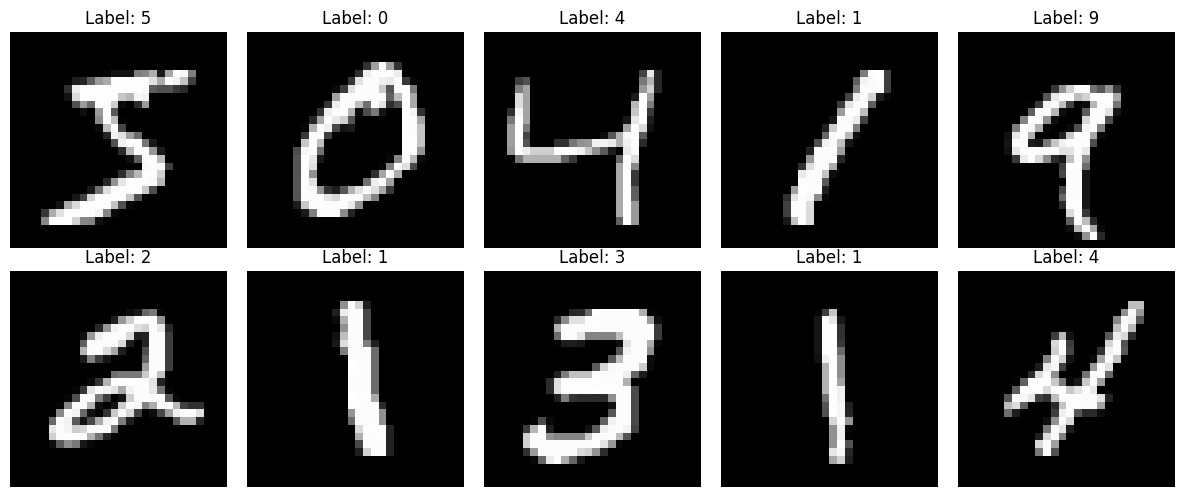

In [3]:
plt.figure(figsize=(12, 5))

for i in range(10):

    image, label = train_data[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Label: {label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# Get unique classes from the dataset
classes = torch.unique(train_data.targets)

print("Actual classes:", classes.tolist())
print("Total classes:", len(classes))

Actual classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Total classes: 10


In [5]:
class CNNModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv_layers = nn.Sequential(

            # First convolution layer
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Second convolution layer
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.fc_layers = nn.Sequential(

            nn.Flatten(),

            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):

        x = self.conv_layers(x)
        x = self.fc_layers(x)

        return x


cnn_model = CNNModel().to(device)

print(cnn_model)

CNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [6]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

In [ ]:
epochs = 10
loss_history = []
accuracy_history = []

for epoch in range(epochs):

    cnn_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for X, y in train_loader:

        # Move data to GPU
        X, y = X.to(device), y.to(device)

        # Forward pass
        y_pred = cnn_model(X)

        # Calculate loss
        loss = loss_fn(y_pred, y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Calculate loss and accuracy
        total_loss += loss.item() * y.size(0)

        predicted = y_pred.argmax(dim=1)

        correct += (predicted == y).sum().item()
        total += y.size(0)

    epoch_loss = total_loss / total
    accuracy = 100 * correct / total

    loss_history.append(epoch_loss)
    accuracy_history.append(accuracy)

    print(
        f"Epoch: {epoch+1}/{epochs} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {accuracy:.2f}%"
    )

Epoch: 1/10 | Loss: 0.2194 | Accuracy: 93.25%
Epoch: 2/10 | Loss: 0.0573 | Accuracy: 98.20%
Epoch: 3/10 | Loss: 0.0398 | Accuracy: 98.75%
Epoch: 4/10 | Loss: 0.0299 | Accuracy: 99.06%
Epoch: 5/10 | Loss: 0.0229 | Accuracy: 99.28%
Epoch: 6/10 | Loss: 0.0187 | Accuracy: 99.39%
Epoch: 7/10 | Loss: 0.0154 | Accuracy: 99.49%
Epoch: 8/10 | Loss: 0.0124 | Accuracy: 99.59%


In [ ]:
from sklearn.metrics import classification_report

cnn_model.eval()

y_true = []
y_pred = []

with torch.inference_mode():

    for X, y in test_loader:

        X = X.to(device)

        outputs = cnn_model(X)

        predicted = outputs.argmax(dim=1)

        y_true.extend(y.numpy())
        y_pred.extend(predicted.cpu().numpy())

print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       1.00      0.99      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.98      0.99      0.98       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



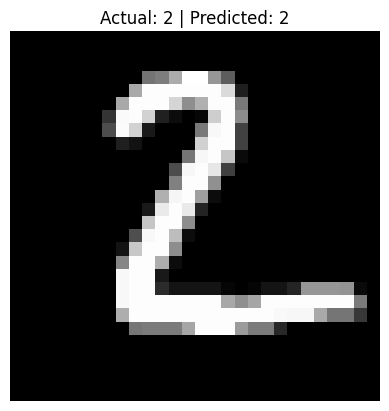

In [ ]:
image, label = test_data[1]

cnn_model.eval()

with torch.inference_mode():

    output = cnn_model(image.unsqueeze(0).to(device))

    predicted = output.argmax(dim=1).item()

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual: {label} | Predicted: {predicted}")
plt.axis("off")
plt.show()

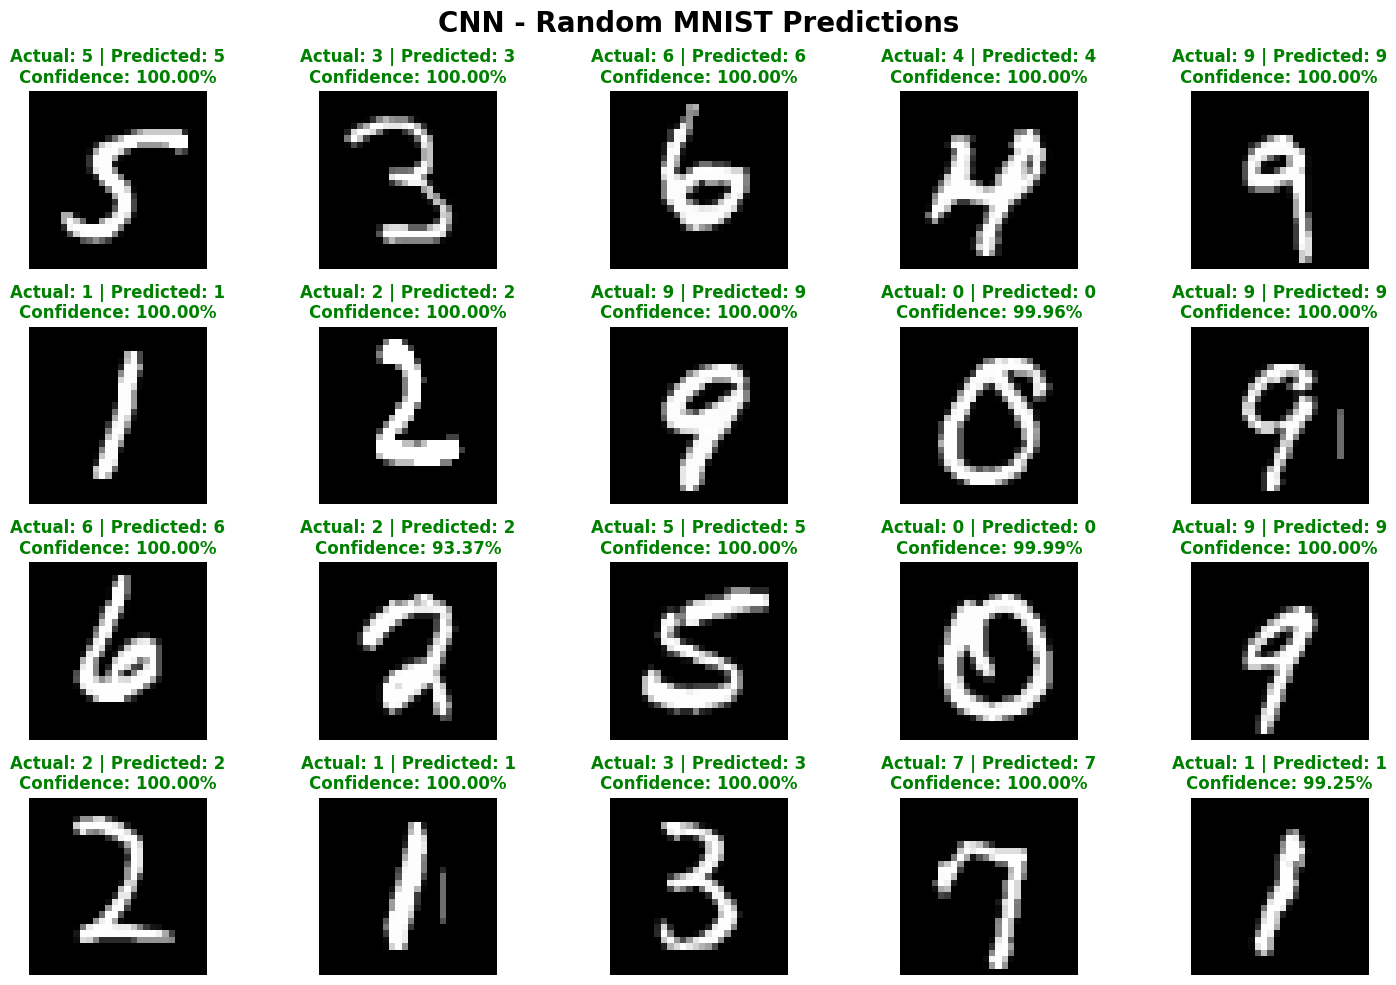

In [ ]:
cnn_model.eval()

# Select 20 random test images
random_indices = np.random.choice(
    len(test_data), size=20, replace=False
)

plt.figure(figsize=(15, 10))

with torch.inference_mode():

    for i, idx in enumerate(random_indices):

        image, label = test_data[idx]

        # Model prediction
        output = cnn_model(image.unsqueeze(0).to(device))

        predicted = output.argmax(dim=1).item()

        # Prediction confidence
        confidence = torch.softmax(output, dim=1).max().item()

        # Green for correct, red for incorrect prediction
        color = "green" if predicted == label else "red"

        plt.subplot(4, 5, i + 1)

        plt.imshow(image.squeeze(), cmap="gray")

        plt.title(
            f"Actual: {label} | Predicted: {predicted}\n"
            f"Confidence: {confidence:.2%}",
            color=color,
            fontweight="bold"
        )

        plt.axis("off")

plt.suptitle("CNN - Random MNIST Predictions", fontsize=20, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
total_params = sum(
    p.numel() for p in cnn_model.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_params)

Total trainable parameters: 206922
